In [48]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import torch
import seaborn as sns
import umap
sns.set()

import torch
from mpl_toolkits.mplot3d import Axes3D 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import rand_score
from sklearn.metrics import normalized_mutual_info_score

In [29]:
data = sc.datasets.paul15()
#print(data.shape)

print(data.obs["paul15_clusters"])

W31105      7MEP
W31106      15Mo
W31107      3Ery
W31108      15Mo
W31109      3Ery
           ...  
W39164      2Ery
W39165    13Baso
W39166      7MEP
W39167      15Mo
W39168      3Ery
Name: paul15_clusters, Length: 2730, dtype: category
Categories (19, str): ['1Ery', '2Ery', '3Ery', '4Ery', ..., '16Neu', '17Neu', '18Eos', '19Lymph']


1255


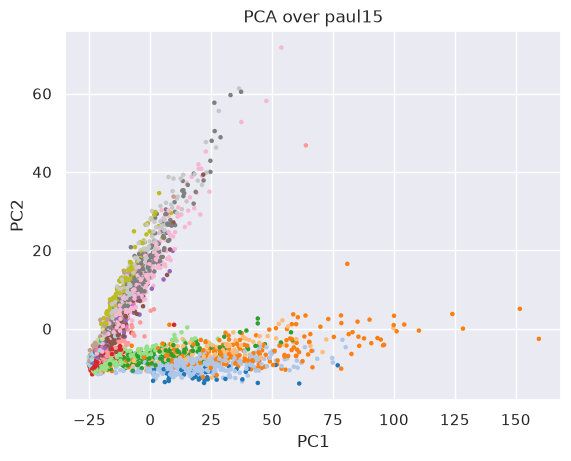

In [25]:
x = np.asarray(data.X, dtype="float32")
labels = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

pca = PCA(n_components=0.90)
pcs = pca.fit_transform(x_scaled)
print(pca.n_components_)
plt.scatter(pcs[:, 0], pcs[:, 1], c=labels, cmap="tab20", s=5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA over paul15")
plt.show()

### KMeans


In [33]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
for k in range(2, 20):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(u)
    print(k,
          round(silhouette_score(u, lab, sample_size=10000, random_state=42), 3),  
          round(calinski_harabasz_score(u, lab)),                                  
          round(davies_bouldin_score(u, lab), 3))  

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2 0.628 6705 0.52
3 0.533 7043 0.691
4 0.464 6366 0.794
5 0.349 5642 1.114
6 0.354 5334 0.971
7 0.283 4854 1.225
8 0.279 4522 1.214
9 0.253 4249 1.248
10 0.25 4006 1.244
11 0.25 3823 1.256
12 0.244 3629 1.229
13 0.229 3464 1.324
14 0.224 3329 1.377
15 0.219 3225 1.38
16 0.225 3136 1.34
17 0.227 3030 1.355
18 0.228 2947 1.36
19 0.219 2861 1.388


/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.39344644192784123
Silhouette Score:  0.21179530024528503
Rand Index:  0.8890487062711321


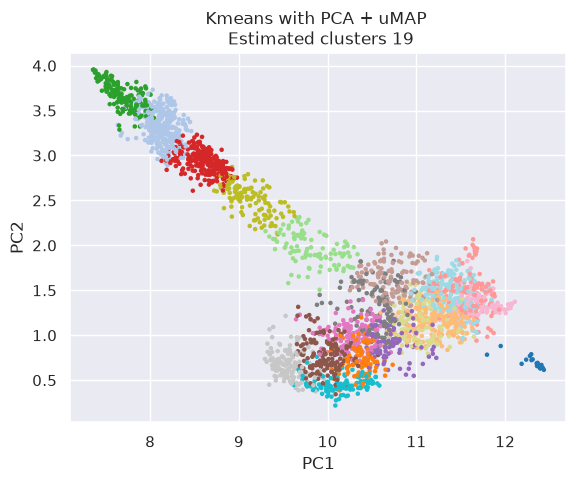

In [46]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(u)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(u, labels))
print("Rand Index: ", rand_score(y_true, labels))

plt.scatter(u[:,0],u[:,1],c=labels,cmap="tab20",s=5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Kmeans with PCA + uMAP \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.39344644192784123
Silhouette Score:  0.21179530024528503
Rand Index:  0.8890487062711321


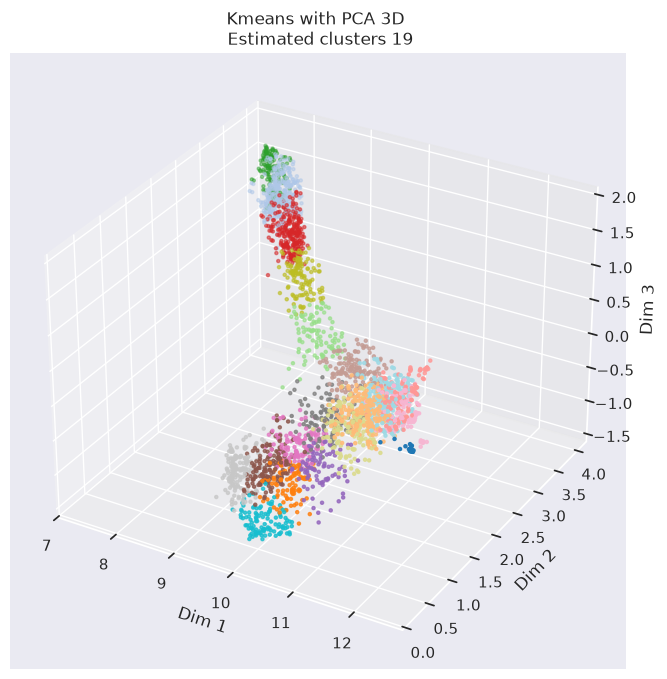

In [45]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(u)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(u, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(u[:,0],u[:,1],u[:,2],c=labels,cmap="tab20",s=5)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("Kmeans with PCA 3D + uMAP \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.3948789555386492
Silhouette Score:  0.3967496156692505
Rand Index:  0.8927076831803838


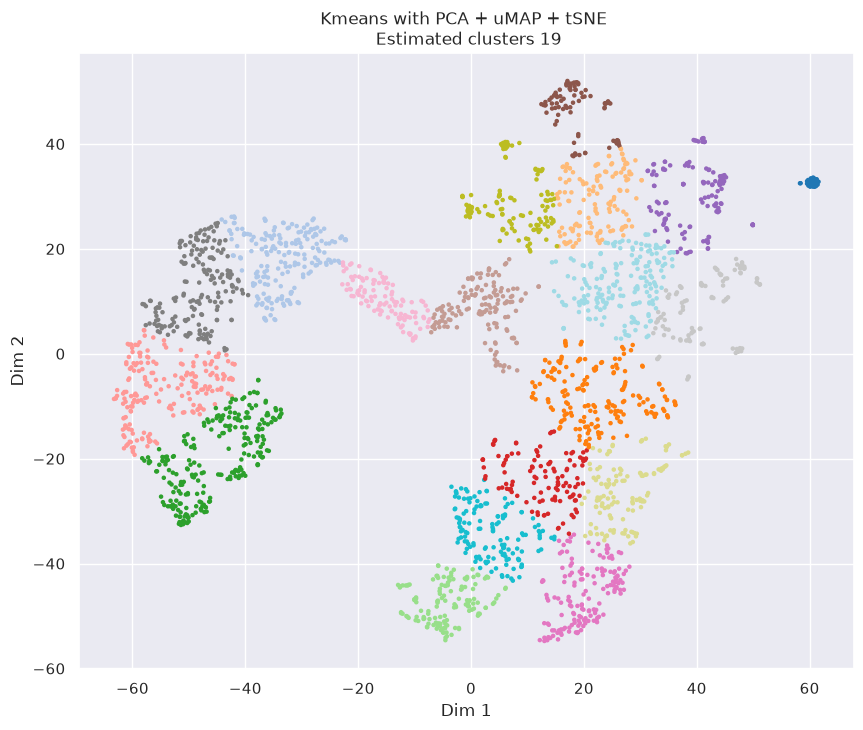

In [52]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
tsne = TSNE(n_components=2,random_state=3)
t = tsne.fit_transform(u)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(t)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(t, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
plt.scatter(t[:,0],t[:,1],c=labels,cmap="tab20",s=5)
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.title("Kmeans with PCA + uMAP + tSNE \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.38602940580042827
Silhouette Score:  0.3342972993850708
Rand Index:  0.8930878087345658


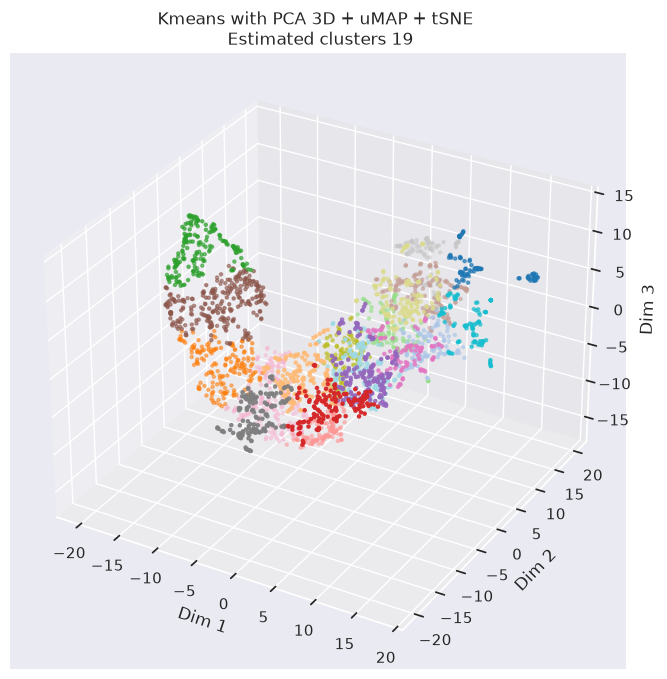

In [53]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(u)
kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(t)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(t, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(t[:,0],t[:,1],t[:,2],c=labels,cmap="tab20",s=5)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("Kmeans with PCA 3D + uMAP + tSNE \n Estimated clusters 19")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


NMI:  0.3206916793294456
Silhouette Score:  0.27960723638534546
Rand Index:  0.8917130750036576


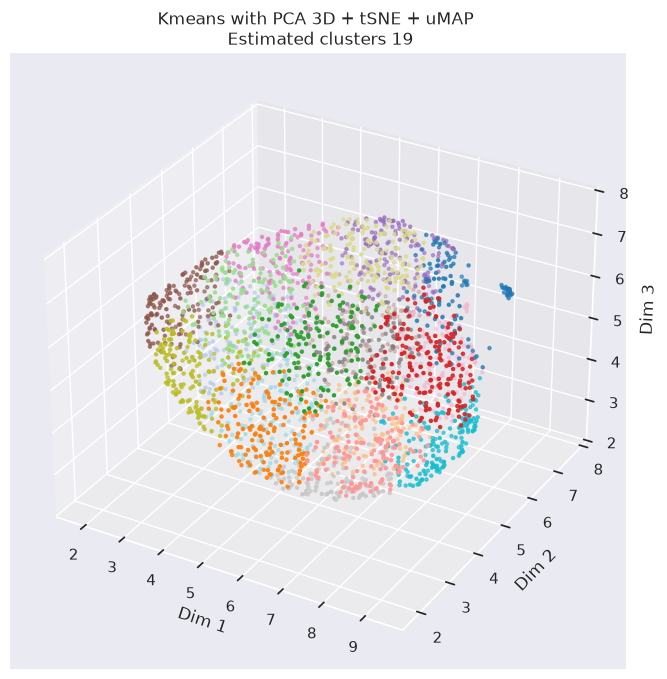

In [54]:
pca = PCA(n_components=0.90)
pca.fit(x_scaled)
scores_pca = pca.transform(x_scaled)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(scores_pca)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(t)

kmeans = KMeans(n_clusters=19,init="k-means++",random_state=24)
labels = kmeans.fit_predict(u)

y_true = data.obs["paul15_clusters"].astype("category").cat.codes.to_numpy()  
print("NMI: ", normalized_mutual_info_score(y_true, labels))
print("Silhouette Score: ", silhouette_score(u, labels))
print("Rand Index: ", rand_score(y_true, labels))

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(u[:,0],u[:,1],u[:,2],c=labels,cmap="tab20",s=5)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("Kmeans with PCA 3D + tSNE + uMAP \n Estimated clusters 19")
plt.show()

### HDBSCAN